# Minimal LISA Link Simulation

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "scripts" / "lisa_link_simulation.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.lisa_link_simulation import LisaLinkSimulationConfig, load_npz_waveform, run_lisa_link_simulation

In [2]:
waveform_file = PROJECT_ROOT / "lisa_link_sim" / "1e5-wave" / "inputs" / "my_waveform_1e5.npz"
t, hplus, hcross = load_npz_waveform(waveform_file)

In [3]:
config = LisaLinkSimulationConfig(
    dt=0.1,
    science_duration=150_000.0,
    burn_in_seconds=600.0,
    edge_taper_seconds=10_000.0,
    frequency_low_hz=1e-5,
    frequency_high_hz=1e-1,
    orbit_duration_factor=5.0,
    orbit_dataset="tcb/ltt",
    gw_dataset="tcb",
    tdi_generation=2,
    tdi_unit="frequency",
    seed=12345,
)

products = run_lisa_link_simulation(
    t,
    hplus,
    hcross,
    work_dir=PROJECT_ROOT / "examples" / "runs" / "minimal_lisa_link_simulation",
    config=config,
    make_plots=True,
)

products.diagnostics

OEM preferred interpolation method ignored, using spline interpolation (see InterpolatedOrbits for details)
You are using an orbit file in a version that might not be fully supported
You are using an orbit file in a version that might not be fully supported
Using default set of locking beatnote frequencies might cause interferometric beatnote frequencies to fall outside the requirement range of 5..25 MHz
You are using a measurement file in a version that might not be fully supported (got '2.1.0', official support up to '2.0')
You are using a GW file in a version that might not be fully supported
You are using an orbit file in a version that might not be fully supported


{'science_samples': 1500000,
 'science_dt': 0.1,
 'science_fft_df_hz': 6.666666666666667e-06,
 'waveform_peak_time': 75000.0,
 'waveform_max_strain': 1.820843155097803e-19,
 'waveform_edge_taper_seconds': 10000.0,
 'waveform_start_amp_over_peak': 0.0,
 'waveform_stop_amp_over_peak': 0.0,
 'time_frame': 'TCB seconds since LISA epoch',
 'sky_frame': 'ICRS right ascension/declination',
 'link_index_convention': 'ij means receiver i, emitter j',
 'gw_dataset': 'tcb',
 'orbit_dataset': 'tcb/ltt',
 'gw_link_unit': 'dimensionless fractional frequency y_ij',
 'gw_link_hz_unit': 'Hz after multiplying by central_freq_hz',
 'tdi_unit': 'frequency',
 'orbit_t0': 61171239.327664,
 'orbit_t1': 61921239.327664,
 'orbit_span': 750000.0,
 'orbit_size': 1251,
 'burn_in_size': 6000,
 'n_waveform': 1500000,
 'n_total': 1506000,
 'orbit_start_lisa': 61470939.377664,
 't_lisa_min': 61470939.377664,
 't_lisa_max': 61621539.277664,
 'gw_link_max_hz': 7.285106781579485e-05,
 'instrument_samples': 1506000,
 'td

In [4]:
for key in ["gw_links_csv", "noisy_links_csv", "noisy_tdi_csv", "gw_tdi_csv", "instrument_h5"]:
    print(f"{key:16s} {getattr(products.paths, key)}")

gw_links_csv     /Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/minimal_lisa_link_simulation/outputs/six_links_gw_only.csv
noisy_links_csv  /Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/minimal_lisa_link_simulation/outputs/six_links_noisy.csv
noisy_tdi_csv    /Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/minimal_lisa_link_simulation/outputs/tdi_michelson_XYZ_AET.csv
gw_tdi_csv       /Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/minimal_lisa_link_simulation/outputs/tdi_gw_only_XYZ_AET.csv
instrument_h5    /Users/shubhanshutiwari/IdeaProjects/LISA-TF/examples/runs/minimal_lisa_link_simulation/outputs/lisa_instrument_output.h5


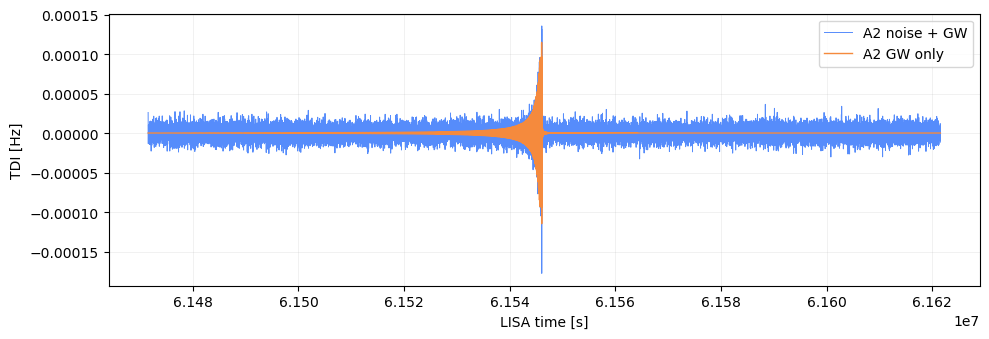

In [5]:
import matplotlib.pyplot as plt
import pandas as pd

noisy = pd.read_csv(products.paths.noisy_tdi_csv, usecols=["t_lisa", "A2"])
signal = pd.read_csv(products.paths.gw_tdi_csv, usecols=["t_lisa", "A2_gw_hz"])
stride = max(1, len(noisy) // 20_000)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(noisy["t_lisa"].iloc[::stride], noisy["A2"].iloc[::stride], lw=0.7, label="A2 noise + GW")
ax.plot(signal["t_lisa"].iloc[::stride], signal["A2_gw_hz"].iloc[::stride], lw=1.0, label="A2 GW only")
ax.set_xlabel("LISA time [s]")
ax.set_ylabel("TDI [Hz]")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()